In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

In [2]:
data_dir = Path("../data/raw")

train_values = pd.read_csv(data_dir / "Training set values.csv")
train_labels = pd.read_csv(data_dir / "Training set labels.csv")
test_values = pd.read_csv(data_dir / "Test set values.csv")
submission = pd.read_csv(data_dir / "SubmissionFormat.csv")

In [3]:
df = train_values.merge(
    train_labels,
    on="id",
    how="inner",
    validate="one_to_one"
)

print("Training dataset:", df.shape)
print("Test dataset:", test_values.shape)

Training dataset: (59400, 41)
Test dataset: (14850, 40)


In [4]:
# Séparation des features et de la target

X = df.drop(columns=["status_group", "id"])
y = df["status_group"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (59400, 39)
y shape: (59400,)


In [5]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (47520, 39)
X_val: (11880, 39)
y_train: (47520,)
y_val: (11880,)


In [6]:
missing_values = pd.DataFrame({
    "Missing Count": X_train.isnull().sum(),
    "Missing Percentage": X_train.isnull().mean() * 100
})

missing_values = missing_values[
    missing_values["Missing Count"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_values.round(2))

,Missing Count,Missing Percentage
scheme_name,23050,48.51
scheme_management,3129,6.58
installer,2917,6.14
funder,2906,6.12
public_meeting,2644,5.56
permit,2443,5.14
subvillage,286,0.60
wpt_name,2,0.00


In [7]:
for col in missing_values.index:

    print(f"\n--- {col} ---")

    missing_mask = X_train[col].isnull()

    distribution = pd.crosstab(
        missing_mask,
        y_train,
        normalize="index"
    ) * 100

    display(distribution.round(2))


--- scheme_name ---


status_group,functional,functional needs repair,non functional
scheme_name,,,
False,56.80,7.49,35.71
True,51.66,7.04,41.31



--- scheme_management ---


status_group,functional,functional needs repair,non functional
scheme_management,,,
False,54.72,7.38,37.90
True,48.42,5.72,45.86



--- installer ---


status_group,functional,functional needs repair,non functional
installer,,,
False,54.30,6.97,38.73
True,54.41,11.86,33.73


... (6 outputs left out)


--- subvillage ---


status_group,functional,functional needs repair,non functional
subvillage,,,
False,54.31,7.31,38.38
True,54.55,0.35,45.10



--- wpt_name ---


status_group,functional,functional needs repair,non functional
wpt_name,,,
False,54.31,7.27,38.42
True,0.00,0.00,100.00


In [8]:
X_train_clean = X_train.copy()
X_val_clean = X_val.copy()
X_test_clean = test_values.drop(columns=["id"]).copy()

In [9]:
missing_cat_cols = [
    "scheme_name",
    "scheme_management",
    "installer",
    "funder",
    "public_meeting",
    "permit",
    "subvillage",
    "wpt_name"
]

for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset[missing_cat_cols] = dataset[missing_cat_cols].fillna("Unknown")

In [10]:
print("Missing values in X_train_clean:",
      X_train_clean[missing_cat_cols].isnull().sum().sum())

print("Missing values in X_val_clean:",
      X_val_clean[missing_cat_cols].isnull().sum().sum())

print("Missing values in X_test_clean:",
      X_test_clean[missing_cat_cols].isnull().sum().sum())

Missing values in X_train_clean: 0
Missing values in X_val_clean: 0
Missing values in X_test_clean: 0


In [11]:
missing_remaining = X_train_clean.isnull().sum()

missing_remaining = missing_remaining[missing_remaining > 0].sort_values(
    ascending=False
)

display(missing_remaining)

Series([], dtype: int64)

In [12]:
for name, dataset in [
    ("Train", X_train_clean),
    ("Validation", X_val_clean),
    ("Test", X_test_clean)
]:
    print(f"{name}: {(dataset['construction_year'] == 0).sum()} zéros")

Train: 16517 zéros
Validation: 4192 zéros
Test: 5260 zéros


In [15]:
for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset["construction_year"] = dataset["construction_year"].replace(0, np.nan)

In [16]:
X_train_clean["construction_year"].isnull().sum()

16517

In [17]:
median_year = X_train_clean["construction_year"].median()

print("Median construction year:", median_year)

Median construction year: 2000.0


In [18]:
for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset["construction_year"] = dataset["construction_year"].fillna(median_year)

In [20]:
X_train_clean["construction_year"].isnull().sum()

0

In [21]:
for name, dataset in [
    ("Train", X_train_clean),
    ("Validation", X_val_clean),
    ("Test", X_test_clean)
]:
    print(f"{name}: {(dataset['longitude'] == 0).sum()} longitudes nulles")

Train: 1442 longitudes nulles
Validation: 370 longitudes nulles
Test: 457 longitudes nulles


In [22]:
for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset["longitude"] = dataset["longitude"].replace(0, np.nan)

In [23]:
X_train_clean["longitude"].isnull().sum()

1442

In [24]:
for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset["longitude_missing"] = dataset["longitude"].isnull().astype(int)

In [25]:
for name, dataset in [
    ("Train", X_train_clean),
    ("Validation", X_val_clean),
    ("Test", X_test_clean)
]:
    print(f"{name}: {(dataset['latitude'] == 0).sum()} latitudes nulles")
    

Train: 0 latitudes nulles
Validation: 0 latitudes nulles
Test: 0 latitudes nulles


In [26]:
for name, dataset in [
    ("Train", X_train_clean),
    ("Validation", X_val_clean),
    ("Test", X_test_clean)
]:
    print(f"{name}: {(dataset['amount_tsh'] == 0).sum()} zéros")

Train: 33265 zéros
Validation: 8374 zéros
Test: 10410 zéros


In [27]:
print("Statistiques de amount_tsh :")
display(X_train_clean["amount_tsh"].describe())

zero_count = (X_train_clean["amount_tsh"] == 0).sum()
zero_percentage = (X_train_clean["amount_tsh"] == 0).mean() * 100

print(f"Nombre de zéros : {zero_count}")
print(f"Pourcentage de zéros : {zero_percentage:.2f}%")

Statistiques de amount_tsh :


count     47520.000000
mean        321.925261
std        3197.240487
min           0.000000
25%           0.000000
50%           0.000000
75%          25.000000
max      350000.000000
Name: amount_tsh, dtype: float64

Nombre de zéros : 33265
Pourcentage de zéros : 70.00%


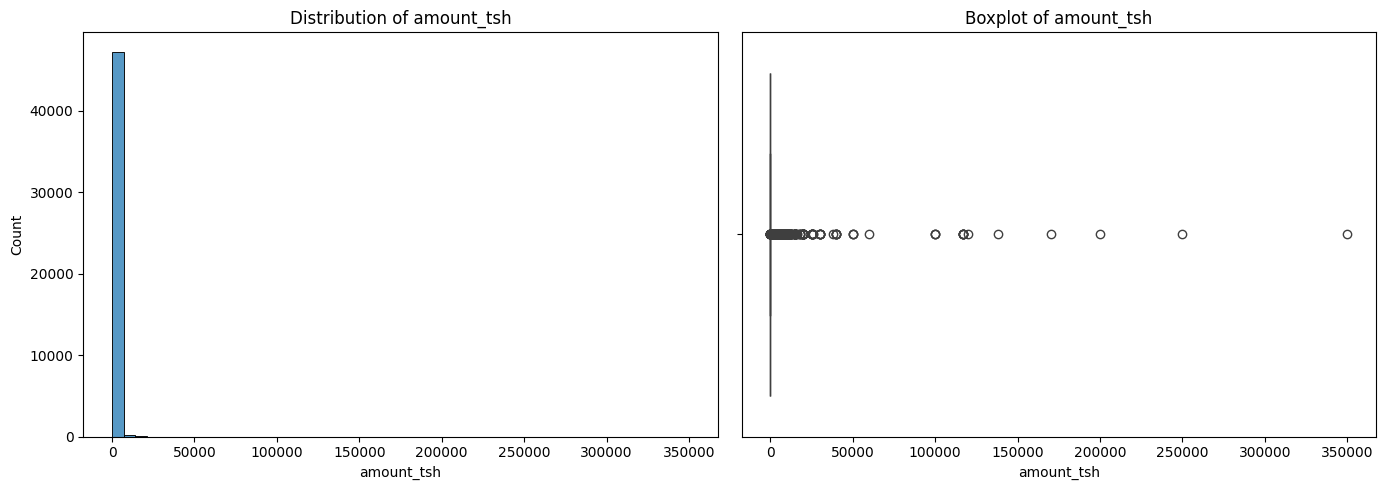

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    X_train_clean["amount_tsh"],
    bins=50,
    ax=axes[0]
)
axes[0].set_title("Distribution of amount_tsh")

sns.boxplot(
    x=X_train_clean["amount_tsh"],
    ax=axes[1]
)
axes[1].set_title("Boxplot of amount_tsh")

plt.tight_layout()
plt.show()

In [29]:
amount_analysis = pd.DataFrame({
    "amount_tsh": X_train_clean["amount_tsh"],
    "status_group": y_train
})

# Pourcentage de zéros par classe
zero_by_status = amount_analysis.groupby("status_group")["amount_tsh"].apply(
    lambda x: (x == 0).mean() * 100
)

print("Pourcentage de zéros par classe :")
display(zero_by_status.round(2))

# Statistiques par classe
print("Statistiques de amount_tsh par classe :")
display(amount_analysis.groupby("status_group")["amount_tsh"].describe().round(2))

Pourcentage de zéros par classe :


status_group
functional                 60.95
functional needs repair    70.09
non functional             82.78
Name: amount_tsh, dtype: float64

Statistiques de amount_tsh par classe :


,count,mean,std,min,25%,50%,75%,max
status_group,,,,,,,,
functional,25807.0,465.92,4142.19,0.0,0.0,0.0,50.0,350000.0
functional needs repair,3454.0,273.47,2104.14,0.0,0.0,0.0,50.0,100000.0
non functional,18259.0,127.57,1203.88,0.0,0.0,0.0,0.0,117000.0


In [30]:
amount_analysis.groupby("status_group")["amount_tsh"].apply(
    lambda x: (x == 0).mean() * 100
).round(2)

status_group
functional                 60.95
functional needs repair    70.09
non functional             82.78
Name: amount_tsh, dtype: float64

In [31]:
for dataset in [X_train_clean, X_val_clean, X_test_clean]:

    dataset["amount_tsh_zero"] = (
        dataset["amount_tsh"] == 0
    ).astype(int)

    dataset["amount_tsh_log"] = np.log1p(
        dataset["amount_tsh"]
    )

In [32]:
for name, dataset in [
    ("Train", X_train_clean),
    ("Validation", X_val_clean),
    ("Test", X_test_clean)
]:
    print(f"{name}: {(dataset['population'] == 0).sum()} zéros")

Train: 17066 zéros
Validation: 4315 zéros
Test: 5453 zéros


In [33]:
for name, dataset in [
    ("Train", X_train_clean),
    ("Validation", X_val_clean),
    ("Test", X_test_clean)
]:
    print(f"\n{name}")
    print(dataset.isnull().sum()[dataset.isnull().sum() > 0])


Train
longitude    1442
dtype: int64

Validation
longitude    370
dtype: int64

Test
longitude    457
dtype: int64


In [42]:
numeric_cols = X_train_clean.select_dtypes(include=[np.number]).columns.tolist()

categorical_cols = X_train_clean.select_dtypes(
    include=["int","object", "bool", "category"]
).columns.tolist()

print("Numeric:", len(numeric_cols))
print(numeric_cols)

print("\nCategorical:", len(categorical_cols))
print(categorical_cols)

Numeric: 12
['amount_tsh', 'gps_height', 'longitude', 'latitude', 'num_private', 'region_code', 'district_code', 'population', 'construction_year', 'longitude_missing', 'amount_tsh_zero', 'amount_tsh_log']

Categorical: 37
['date_recorded', 'funder', 'gps_height', 'installer', 'wpt_name', 'num_private', 'basin', 'subvillage', 'region', 'region_code', 'district_code', 'lga', 'ward', 'population', 'public_meeting', 'recorded_by', 'scheme_management', 'scheme_name', 'permit', 'extraction_type', 'extraction_type_group', 'extraction_type_class', 'management', 'management_group', 'payment', 'payment_type', 'water_quality', 'quality_group', 'quantity', 'quantity_group', 'source', 'source_type', 'source_class', 'waterpoint_type', 'waterpoint_type_group', 'longitude_missing', 'amount_tsh_zero']


In [36]:
for col in ["longitude_missing", "amount_tsh_zero", "amount_tsh_log"]:
    print(f"{col}:")
    print("Présente :", col in X_train_clean.columns)

    if col in X_train_clean.columns:
        print("Type :", X_train_clean[col].dtype)
    print()

longitude_missing:
Présente : True
Type : int32

amount_tsh_zero:
Présente : True
Type : int32

amount_tsh_log:
Présente : True
Type : float64



In [44]:
print(X_train_clean[
    ["longitude_missing", "amount_tsh_zero"]
].dtypes)

print("\nDétection numérique :")
print(X_train_clean.select_dtypes(include=[np.number]).columns.tolist())

longitude_missing    int32
amount_tsh_zero      int32
dtype: object

Détection numérique :
['amount_tsh', 'gps_height', 'longitude', 'latitude', 'num_private', 'region_code', 'district_code', 'population', 'construction_year', 'longitude_missing', 'amount_tsh_zero', 'amount_tsh_log']


In [43]:
numeric_cols = X_train_clean.select_dtypes(include=[np.number]).columns.tolist()

categorical_cols = X_train_clean.select_dtypes(
    include=["object", "bool", "category"]
).columns.tolist()

print("Numeric:", len(numeric_cols))
print("Categorical:", len(categorical_cols))

Numeric: 12
Categorical: 30


In [45]:
print(X_train_clean["recorded_by"].nunique())

1


In [46]:
for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset.drop(columns=["recorded_by"], inplace=True)

In [47]:
print("recorded_by" in X_train_clean.columns)

False


In [48]:
pairs = [
    ("quantity", "quantity_group"),
    ("source", "source_type"),
    ("source", "source_class"),
    ("extraction_type", "extraction_type_group"),
    ("extraction_type_group", "extraction_type_class"),
    ("waterpoint_type", "waterpoint_type_group"),
    ("water_quality", "quality_group"),
    ("payment", "payment_type"),
    ("management", "management_group")
]

for col1, col2 in pairs:
    same = (X_train_clean[col1] == X_train_clean[col2]).mean() * 100

    print(f"{col1} / {col2} : {same:.2f}% de valeurs identiques")

quantity / quantity_group : 100.00% de valeurs identiques
source / source_type : 62.46% de valeurs identiques
source / source_class : 0.12% de valeurs identiques
extraction_type / extraction_type_group : 95.88% de valeurs identiques
extraction_type_group / extraction_type_class : 67.30% de valeurs identiques
waterpoint_type / waterpoint_type_group : 89.76% de valeurs identiques
water_quality / quality_group : 13.11% de valeurs identiques
payment / payment_type : 58.26% de valeurs identiques
management / management_group : 5.30% de valeurs identiques


In [49]:
for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset.drop(columns=["quantity_group"], inplace=True)

In [50]:
source_comparison = pd.crosstab(
    X_train_clean["source"],
    X_train_clean["source_type"]
)

display(source_comparison)

source_type,borehole,dam,other,rainwater harvesting,river/lake,shallow well,spring
source,,,,,,,
dam,0,518,0,0,0,0,0
hand dtw,698,0,0,0,0,0,0
lake,0,0,0,0,586,0,0
machine dbh,8813,0,0,0,0,0,0
other,0,0,175,0,0,0,0
rainwater harvesting,0,0,0,1859,0,0,0
river,0,0,0,0,7685,0,0
shallow well,0,0,0,0,0,13507,0
spring,0,0,0,0,0,0,13620


In [51]:
for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset.drop(columns=["source_type"], inplace=True)

In [52]:
display(pd.crosstab(
    X_train_clean["source"],
    X_train_clean["source_class"]
))

source_class,groundwater,surface,unknown
source,,,
dam,0,518,0
hand dtw,698,0,0
lake,0,586,0
machine dbh,8813,0,0
other,0,0,175
rainwater harvesting,0,1859,0
river,0,7685,0
shallow well,13507,0,0
spring,13620,0,0


In [53]:
for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset.drop(columns=["source_class"], inplace=True)

In [56]:
pd.crosstab(
    X_train_clean["extraction_type"],
    X_train_clean["extraction_type_group"]
)

extraction_type_group,afridev,gravity,india mark ii,india mark iii,mono,nira/tanira,other,other handpump,other motorpump,rope pump,submersible,swn 80,wind-powered
extraction_type,,,,,,,,,,,,,
afridev,1435,0,0,0,0,0,0,0,0,0,0,0,0
cemo,0,0,0,0,0,0,0,0,70,0,0,0,0
climax,0,0,0,0,0,0,0,0,24,0,0,0,0
gravity,0,21448,0,0,0,0,0,0,0,0,0,0,0
india mark ii,0,0,1928,0,0,0,0,0,0,0,0,0,0
india mark iii,0,0,0,73,0,0,0,0,0,0,0,0,0
ksb,0,0,0,0,0,0,0,0,0,0,1124,0,0
mono,0,0,0,0,2261,0,0,0,0,0,0,0,0
nira/tanira,0,0,0,0,0,6526,0,0,0,0,0,0,0


In [57]:
pd.crosstab(
    X_train_clean["extraction_type"],
    X_train_clean["extraction_type_class"]
)

extraction_type_class,gravity,handpump,motorpump,other,rope pump,submersible,wind-powered
extraction_type,,,,,,,
afridev,0,1435,0,0,0,0,0
cemo,0,0,70,0,0,0,0
climax,0,0,24,0,0,0,0
gravity,21448,0,0,0,0,0,0
india mark ii,0,1928,0,0,0,0,0
india mark iii,0,73,0,0,0,0,0
ksb,0,0,0,0,0,1124,0
mono,0,0,2261,0,0,0,0
nira/tanira,0,6526,0,0,0,0,0


In [58]:
pd.crosstab(
    X_train_clean["extraction_type_group"],
    X_train_clean["extraction_type_class"]
)

extraction_type_class,gravity,handpump,motorpump,other,rope pump,submersible,wind-powered
extraction_type_group,,,,,,,
afridev,0,1435,0,0,0,0,0
gravity,21448,0,0,0,0,0,0
india mark ii,0,1928,0,0,0,0,0
india mark iii,0,73,0,0,0,0,0
mono,0,0,2261,0,0,0,0
nira/tanira,0,6526,0,0,0,0,0
other,0,0,0,5193,0,0,0
other handpump,0,292,0,0,0,0,0
other motorpump,0,0,94,0,0,0,0


In [59]:
for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset.drop(
        columns=["extraction_type_group", "extraction_type_class"],
        inplace=True
    )

In [60]:
display(pd.crosstab(
    X_train_clean["waterpoint_type"],
    X_train_clean["waterpoint_type_group"]
))

waterpoint_type_group,cattle trough,communal standpipe,dam,hand pump,improved spring,other
waterpoint_type,,,,,,
cattle trough,89,0,0,0,0,0
communal standpipe,0,22778,0,0,0,0
communal standpipe multiple,0,4864,0,0,0,0
dam,0,0,5,0,0,0
hand pump,0,0,0,14015,0,0
improved spring,0,0,0,0,631,0
other,0,0,0,0,0,5138


In [61]:
for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset.drop(columns=["waterpoint_type_group"], inplace=True)

In [62]:
display(pd.crosstab(
    X_train_clean["water_quality"],
    X_train_clean["quality_group"]
))

quality_group,colored,fluoride,good,milky,salty,unknown
water_quality,,,,,,
coloured,403,0,0,0,0,0
fluoride,0,165,0,0,0,0
fluoride abandoned,0,14,0,0,0,0
milky,0,0,0,658,0,0
salty,0,0,0,0,3903,0
salty abandoned,0,0,0,0,276,0
soft,0,0,40598,0,0,0
unknown,0,0,0,0,0,1503


In [63]:
for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset.drop(columns=["quality_group"], inplace=True)

In [64]:
display(pd.crosstab(
    X_train_clean["payment"],
    X_train_clean["payment_type"]
))

payment_type,annually,monthly,never pay,on failure,other,per bucket,unknown
payment,,,,,,,
never pay,0,0,20287,0,0,0,0
other,0,0,0,0,865,0,0
pay annually,2938,0,0,0,0,0,0
pay monthly,0,6644,0,0,0,0,0
pay per bucket,0,0,0,0,0,7161,0
pay when scheme fails,0,0,0,3093,0,0,0
unknown,0,0,0,0,0,0,6532


In [65]:
for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset.drop(columns=["payment_type"], inplace=True)

In [66]:
display(pd.crosstab(
    X_train_clean["management"],
    X_train_clean["management_group"]
))

management_group,commercial,other,parastatal,unknown,user-group
management,,,,,
company,534,0,0,0,0
other,0,669,0,0,0
other - school,0,80,0,0,0
parastatal,0,0,1397,0,0
private operator,1566,0,0,0,0
trust,63,0,0,0,0
unknown,0,0,0,453,0
vwc,0,0,0,0,32449
water authority,731,0,0,0,0


In [67]:
for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset.drop(columns=["management_group"], inplace=True)

In [68]:
X_train_clean["date_recorded"].head()

43360    2011-07-27
7263     2011-03-23
2486     2011-03-07
313      2011-07-31
52726    2011-03-10
Name: date_recorded, dtype: object

In [69]:
X_train_clean["date_recorded"].describe()

count          47520
unique           349
top       2011-03-17
freq             474
Name: date_recorded, dtype: object

In [70]:
for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset["date_recorded"] = pd.to_datetime(
        dataset["date_recorded"],
        errors="coerce"
    )

In [71]:
for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset["recorded_year"] = dataset["date_recorded"].dt.year
    dataset["recorded_month"] = dataset["date_recorded"].dt.month

In [72]:
X_train_clean[
    ["date_recorded", "recorded_year", "recorded_month"]
].head()

,date_recorded,recorded_year,recorded_month
43360,2011-07-27,2011,7
7263,2011-03-23,2011,3
2486,2011-03-07,2011,3
313,2011-07-31,2011,7
52726,2011-03-10,2011,3


In [73]:
for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset.drop(columns=["date_recorded"], inplace=True)

# Data audit

In [74]:
print("Train :", X_train_clean.shape)
print("Validation :", X_val_clean.shape)
print("Test :", X_test_clean.shape)

print("\nColonnes restantes :")
display(pd.DataFrame({
    "dtype": X_train_clean.dtypes,
    "nunique": X_train_clean.nunique(),
    "missing": X_train_clean.isnull().sum()
}))

Train : (47520, 33)
Validation : (11880, 33)
Test : (14850, 33)

Colonnes restantes :


,dtype,nunique,missing
amount_tsh,float64,94,0
funder,object,1715,0
gps_height,int64,2401,0
installer,object,1929,0
longitude,float64,46028,1442
latitude,float64,46027,0
wpt_name,object,30660,0
num_private,int64,59,0
basin,object,9,0
subvillage,object,17232,0


In [75]:
high_cardinality_cols = [
    "wpt_name",
    "subvillage",
    "ward",
    "scheme_name",
    "installer",
    "funder"
]

for col in high_cardinality_cols:
    print(f"\n--- {col} ---")
    print("Nombre de catégories :", X_train_clean[col].nunique())
    display(X_train_clean[col].value_counts().head(10))


--- wpt_name ---
Nombre de catégories : 30660


wpt_name
none               2879
Shuleni            1416
Zahanati            675
Msikitini           424
Kanisani            253
Ofisini             212
Bombani             209
Sokoni              205
School              167
Shule Ya Msingi     160
Name: count, dtype: int64


--- subvillage ---
Nombre de catégories : 17232


subvillage
Shuleni     420
Majengo     409
Madukani    404
Kati        306
Unknown     286
Mtakuja     211
Sokoni      191
M           150
Mbuyuni     132
Muungano    130
Name: count, dtype: int64


--- ward ---
Nombre de catégories : 2082


ward
Igosi           257
Imalinyi        209
Siha Kati       189
Mdandu          178
Nduruma         176
Mishamo         164
Chalinze        163
Msindo          157
Maji ya Chai    154
Kitunda         153
Name: count, dtype: int64

... (2 outputs left out)


--- installer ---
Nombre de catégories : 1929


installer
DWE           13978
Unknown        2919
Government     1458
RWE             960
Commu           846
DANIDA          842
KKKT            709
Hesawa          668
0               607
TCRS            576
Name: count, dtype: int64


--- funder ---
Nombre de catégories : 1715


funder
Government Of Tanzania    7321
Unknown                   2909
Danida                    2491
Hesawa                    1760
Rwssp                     1107
World Bank                1058
Kkkt                      1019
World Vision              1001
Unicef                     840
Tasaf                      719
Name: count, dtype: int64

In [76]:
for col in high_cardinality_cols:

    counts = X_train_clean[col].value_counts()

    print(f"\n--- {col} ---")
    print("Total catégories :", len(counts))
    print("Catégories présentes 1 seule fois :", (counts == 1).sum())
    print("Catégories présentes 5 fois ou moins :", (counts <= 5).sum())
    print("Catégories présentes 10 fois ou moins :", (counts <= 10).sum())

    print(
        "Observations appartenant à des catégories de 10 occurrences ou moins :",
        f"{counts[counts <= 10].sum() / len(X_train_clean) * 100:.2f}%"
    )


--- wpt_name ---
Total catégories : 30660
Catégories présentes 1 seule fois : 27224
Catégories présentes 5 fois ou moins : 30253
Catégories présentes 10 fois ou moins : 30484
Observations appartenant à des catégories de 10 occurrences ou moins : 76.71%

--- subvillage ---
Total catégories : 17232
Catégories présentes 1 seule fois : 8948
Catégories présentes 5 fois ou moins : 15838
Catégories présentes 10 fois ou moins : 16815
Observations appartenant à des catégories de 10 occurrences ou moins : 74.29%

--- ward ---
Total catégories : 2082
Catégories présentes 1 seule fois : 53
Catégories présentes 5 fois ou moins : 316
Catégories présentes 10 fois ou moins : 692
Observations appartenant à des catégories de 10 occurrences ou moins : 8.43%

--- scheme_name ---
Total catégories : 2563
Catégories présentes 1 seule fois : 709
Catégories présentes 5 fois ou moins : 1561
Catégories présentes 10 fois ou moins : 1985
Observations appartenant à des catégories de 10 occurrences ou moins : 14.34

In [77]:
results = []

for col in high_cardinality_cols:
    counts = X_train_clean[col].value_counts()

    results.append({
        "variable": col,
        "categories": len(counts),
        "singletons": (counts == 1).sum(),
        "categories_le_5": (counts <= 5).sum(),
        "categories_le_10": (counts <= 10).sum(),
        "observations_le_10_pct": (
            counts[counts <= 10].sum() / len(X_train_clean) * 100
        )
    })

display(pd.DataFrame(results).round(2))

,variable,categories,singletons,categories_le_5,categories_le_10,observations_le_10_pct
0,wpt_name,30660,27224,30253,30484,76.71
1,subvillage,17232,8948,15838,16815,74.29
2,ward,2082,53,316,692,8.43
3,scheme_name,2563,709,1561,1985,14.34
4,installer,1929,971,1435,1576,7.25
5,funder,1715,868,1250,1357,5.94


In [78]:
for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset.drop(columns=["wpt_name"], inplace=True)

In [79]:
geo_pairs = [
    ("lga", "region"),
    ("ward", "lga"),
    ("subvillage", "ward")
]

for child, parent in geo_pairs:

    mapping = (
        X_train_clean.groupby(child)[parent]
        .nunique()
    )

    print(f"\n{child} → {parent}")
    print("Nombre de catégories :", len(mapping))
    print("Catégories associées à un seul parent :", (mapping == 1).sum())
    print("Catégories associées à plusieurs parents :", (mapping > 1).sum())
    print("Maximum de parents associés :", mapping.max())


lga → region
Nombre de catégories : 124
Catégories associées à un seul parent : 124
Catégories associées à plusieurs parents : 0
Maximum de parents associés : 1

ward → lga
Nombre de catégories : 2082
Catégories associées à un seul parent : 1994
Catégories associées à plusieurs parents : 88
Maximum de parents associés : 4

subvillage → ward
Nombre de catégories : 17232
Catégories associées à un seul parent : 15080
Catégories associées à plusieurs parents : 2152
Maximum de parents associés : 197


In [80]:
rare_cols = ["ward", "scheme_name", "installer", "funder"]
min_frequency = 10

# Identifier les catégories fréquentes uniquement sur le train
for col in rare_cols:
    frequent_categories = (
        X_train_clean[col]
        .value_counts()
        .loc[lambda counts: counts > min_frequency]
        .index
    )

    # Appliquer la même règle au train, validation et test
    for dataset in [X_train_clean, X_val_clean, X_test_clean]:
        dataset[col] = dataset[col].where(
            dataset[col].isin(frequent_categories),
            "Other"
        )

# Supprimer subvillage
for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset.drop(columns=["subvillage"], inplace=True)

In [81]:
for col in rare_cols:
    print(f"\n{col}")
    print("Nombre de catégories :", X_train_clean[col].nunique())
    print(X_train_clean[col].value_counts().head(10))
    


ward
Nombre de catégories : 1391
ward
Other           4008
Igosi            257
Imalinyi         209
Siha Kati        189
Mdandu           178
Nduruma          176
Mishamo          164
Chalinze         163
Msindo           157
Maji ya Chai     154
Name: count, dtype: int64

scheme_name
Nombre de catégories : 579
scheme_name
Unknown                        23050
Other                           6812
K                                548
Borehole                         435
Chalinze wate                    325
M                                322
DANIDA                           310
Government                       251
Ngana water supplied scheme      211
wanging'ombe water supply s      208
Name: count, dtype: int64

installer
Nombre de catégories : 354
installer
DWE           13978
Other          3447
Unknown        2919
Government     1458
RWE             960
Commu           846
DANIDA          842
KKKT            709
Hesawa          668
0               607
Name: count, dtype: int64

fu

In [82]:
for col in ["ward", "scheme_name", "installer", "funder"]:
    print(
        f"{col}: {X_train_clean[col].nunique()} catégories"
    )
    print(
        "Nombre regroupé dans Other :",
        (X_train_clean[col] == "Other").sum()
    )

ward: 1391 catégories
Nombre regroupé dans Other : 4008
scheme_name: 579 catégories
Nombre regroupé dans Other : 6812
installer: 354 catégories
Nombre regroupé dans Other : 3447
funder: 359 catégories
Nombre regroupé dans Other : 2824


In [83]:
print("Shape :", X_train_clean.shape)

print("\nValeurs manquantes :")
print(X_train_clean.isnull().sum()[X_train_clean.isnull().sum() > 0])

print("\nTypes des variables :")
print(X_train_clean.dtypes.value_counts())

print("\nColonnes restantes :")
print(X_train_clean.columns.tolist())

Shape : (47520, 31)

Valeurs manquantes :
longitude    1442
dtype: int64

Types des variables :
object     17
float64     5
int64       5
int32       4
Name: count, dtype: int64

Colonnes restantes :
['amount_tsh', 'funder', 'gps_height', 'installer', 'longitude', 'latitude', 'num_private', 'basin', 'region', 'region_code', 'district_code', 'lga', 'ward', 'population', 'public_meeting', 'scheme_management', 'scheme_name', 'permit', 'construction_year', 'extraction_type', 'management', 'payment', 'water_quality', 'quantity', 'source', 'waterpoint_type', 'longitude_missing', 'amount_tsh_zero', 'amount_tsh_log', 'recorded_year', 'recorded_month']


In [84]:
# Identifier automatiquement les colonnes numériques
numeric_cols = X_train_clean.select_dtypes(
    include=[np.number]
).columns.tolist()

# Identifier les colonnes catégorielles
categorical_cols = X_train_clean.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Variables numériques :", len(numeric_cols))
print(numeric_cols)

print("\nVariables catégorielles :", len(categorical_cols))
print(categorical_cols)

Variables numériques : 14
['amount_tsh', 'gps_height', 'longitude', 'latitude', 'num_private', 'region_code', 'district_code', 'population', 'construction_year', 'longitude_missing', 'amount_tsh_zero', 'amount_tsh_log', 'recorded_year', 'recorded_month']

Variables catégorielles : 17
['funder', 'installer', 'basin', 'region', 'lga', 'ward', 'public_meeting', 'scheme_management', 'scheme_name', 'permit', 'extraction_type', 'management', 'payment', 'water_quality', 'quantity', 'source', 'waterpoint_type']


In [85]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [ ]:
from sklearn.preprocessing import OneHotEncoder

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

In [87]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

In [88]:
print("Variables numériques :", len(numeric_cols))
print("Variables catégorielles :", len(categorical_cols))

print("\nTotal :", len(numeric_cols) + len(categorical_cols))
print("Colonnes du dataset :", X_train_clean.shape[1])

Variables numériques : 14
Variables catégorielles : 17

Total : 31
Colonnes du dataset : 31


In [90]:
for dataset in [X_train_clean, X_val_clean, X_test_clean]:
    dataset[categorical_cols] = dataset[categorical_cols].astype(str)

In [91]:
X_train_processed = preprocessor.fit_transform(X_train_clean)

print("Shape après preprocessing :", X_train_processed.shape)
print("Type :", type(X_train_processed))

Shape après preprocessing : (47520, 2936)
Type : <class 'scipy.sparse._csr.csr_matrix'>


In [92]:
X_val_processed = preprocessor.transform(X_val_clean)

print("Shape validation :", X_val_processed.shape)
print("Shape train :", X_train_processed.shape)

Shape validation : (11880, 2936)
Shape train : (47520, 2936)


In [93]:
X_test_processed = preprocessor.transform(X_test_clean)

print("Shape test :", X_test_processed.shape)

Shape test : (14850, 2936)


In [94]:
print("Train :", X_train_processed.shape)
print("Validation :", X_val_processed.shape)
print("Test :", X_test_processed.shape)

Train : (47520, 2936)
Validation : (11880, 2936)
Test : (14850, 2936)


In [95]:
from pathlib import Path

artifacts_dir = Path("../artifacts")
artifacts_dir.mkdir(exist_ok=True)

In [96]:
import joblib

joblib.dump(preprocessor, artifacts_dir / "preprocessor.joblib")

joblib.dump(X_train_processed, artifacts_dir / "X_train_processed.joblib")
joblib.dump(X_val_processed, artifacts_dir / "X_val_processed.joblib")
joblib.dump(X_test_processed, artifacts_dir / "X_test_processed.joblib")

joblib.dump(y_train, artifacts_dir / "y_train.joblib")
joblib.dump(y_val, artifacts_dir / "y_val.joblib")

joblib.dump(test_values["id"], artifacts_dir / "test_ids.joblib")

['..\\artifacts\\test_ids.joblib']